In [1]:
import os
import sys

sys.path.append(os.path.abspath(".."))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

import django
django.setup()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_engine.models import IndicadorEconomico

In [9]:
filas = (
    IndicadorEconomico.objects
    .filter(indicador="uf")
    .order_by("fecha")
    .values("fecha", "valor")
)
uf = pd.DataFrame.from_records(filas)
uf["fecha"] = pd.to_datetime(uf["fecha"])
uf["valor"] = uf["valor"].astype(float)
uf = uf.set_index("fecha")["valor"]

print(uf.head(3))
print(uf.tail(3))
print(len(uf))

fecha
1977-08-01    389.10
1977-08-02    389.51
1977-08-03    389.91
Name: valor, dtype: float64
fecha
2026-11-07    41284.83
2026-11-08    41290.15
2026-11-09    41295.46
Name: valor, dtype: float64
17996


In [10]:
uf_dia9 = uf[uf.index.day == 9]

# Variación mensual en %, fechada en el mes del IPC que representa (2 meses antes)
inflacion_mensual = uf_dia9.pct_change() * 100
inflacion_mensual.index = (inflacion_mensual.index - pd.DateOffset(months=2)).to_period("M")
inflacion_mensual = inflacion_mensual.dropna()

# Inflación acumulada en 12 meses, la que se reporta en las noticias
inflacion_12m = (uf_dia9 / uf_dia9.shift(12) - 1) * 100
inflacion_12m.index = (inflacion_12m.index - pd.DateOffset(months=2)).to_period("M")
inflacion_12m = inflacion_12m.dropna()

print(inflacion_mensual.tail(6).round(2))
print(inflacion_12m.tail(6).round(2))

fecha
2026-04    1.3
2026-05    0.2
2026-06    0.0
2026-07    0.1
2026-08    0.6
2026-09    0.4
Freq: M, Name: valor, dtype: float64
fecha
2026-04    3.96
2026-05    3.96
2026-06    4.37
2026-07    3.55
2026-08    4.17
2026-09    4.17
Freq: M, Name: valor, dtype: float64


In [7]:
filas = (
    IndicadorEconomico.objects
    .filter(indicador="uf")
    .order_by("fecha")
    .values("fecha", "valor")
)
uf = pd.DataFrame.from_records(filas)
uf["fecha"] = pd.to_datetime(uf["fecha"])
uf["valor"] = uf["valor"].astype(float)
uf = uf.set_index("fecha")["valor"]

print(uf.head(3))
print(uf.tail(3))
print(len(uf))

fecha
1977-08-01    389.10
1977-08-02    389.51
1977-08-03    389.91
Name: valor, dtype: float64
fecha
2026-11-07    41284.83
2026-11-08    41290.15
2026-11-09    41295.46
Name: valor, dtype: float64
17996


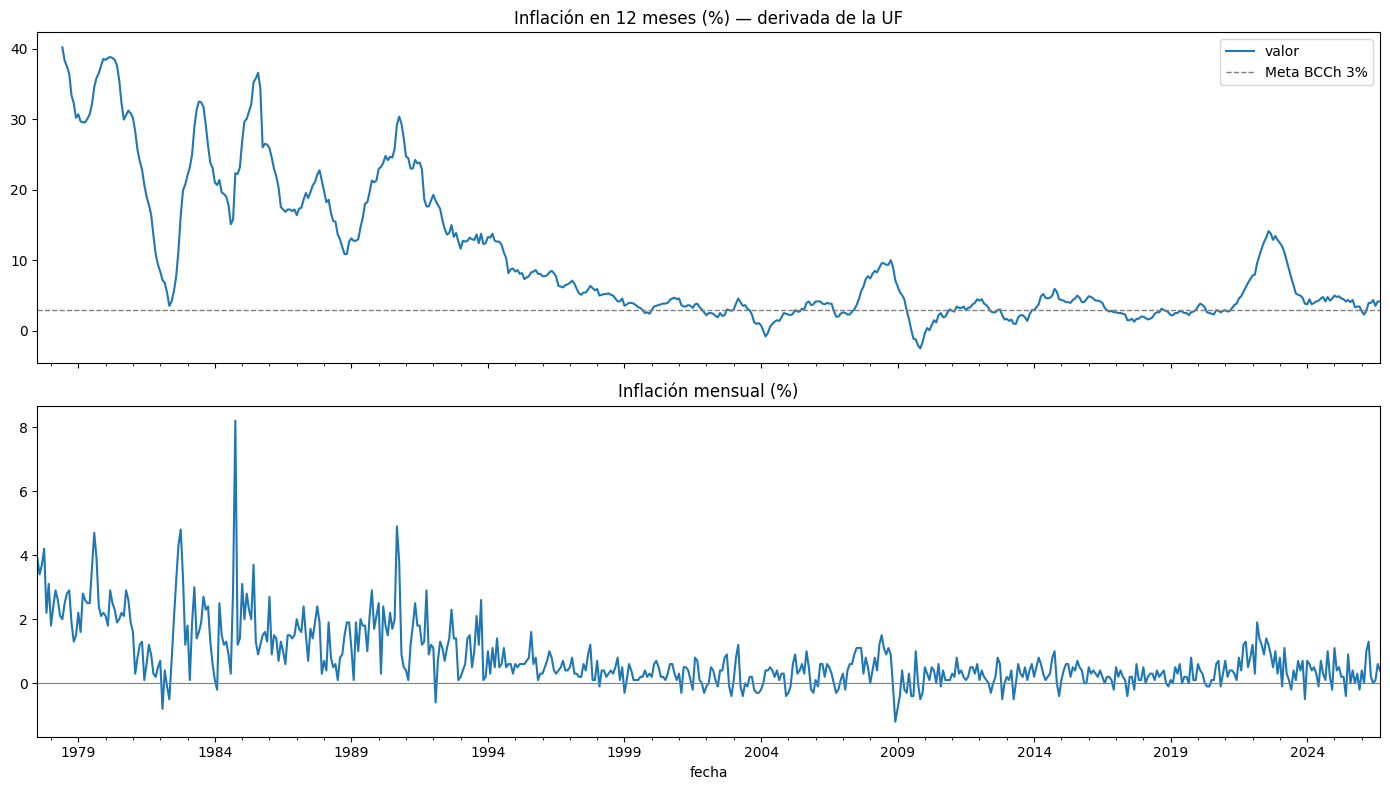

In [8]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

inflacion_12m.plot(ax=ejes[0])
ejes[0].set_title("Inflación en 12 meses (%) — derivada de la UF")
ejes[0].axhline(3, color="gray", linestyle="--", linewidth=1, label="Meta BCCh 3%")
ejes[0].legend()

inflacion_mensual.plot(ax=ejes[1])
ejes[1].set_title("Inflación mensual (%)")
ejes[1].axhline(0, color="gray", linewidth=0.8)

plt.tight_layout()
plt.show()

In [11]:
# Estimar el AR(1)

from statsmodels.tsa.ar_model import AutoReg

muestra = inflacion_mensual["2001-01":]

modelo = AutoReg(muestra.to_numpy(), lags=1, trend="c").fit()
print(modelo.summary())

a, b = modelo.params
sigma = np.std(modelo.resid, ddof=2)
media_mensual = a / (1 - b)
media_anual = ((1 + media_mensual / 100) ** 12 - 1) * 100

print(f"\na (nivel)          = {a:.4f}")
print(f"b (persistencia)   = {b:.4f}")
print(f"sigma (shock)      = {sigma:.4f} puntos porcentuales por mes")
print(f"Media de largo plazo: {media_mensual:.3f}% mensual ≈ {media_anual:.2f}% anual")
if 0 < b < 1:
    print(f"Vida media de un shock: {np.log(0.5) / np.log(b):.1f} meses")

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  308
Model:                     AutoReg(1)   Log Likelihood                -146.941
Method:               Conditional MLE   S.D. of innovations              0.390
Date:                Mon, 19 Oct 2026   AIC                            299.882
Time:                        16:05:38   BIC                            311.073
Sample:                             1   HQIC                           304.357
                                  309                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1942      0.028      7.025      0.000       0.140       0.248
y.L1           0.3785      0.053      7.176      0.000       0.275       0.482
                                    Roots           

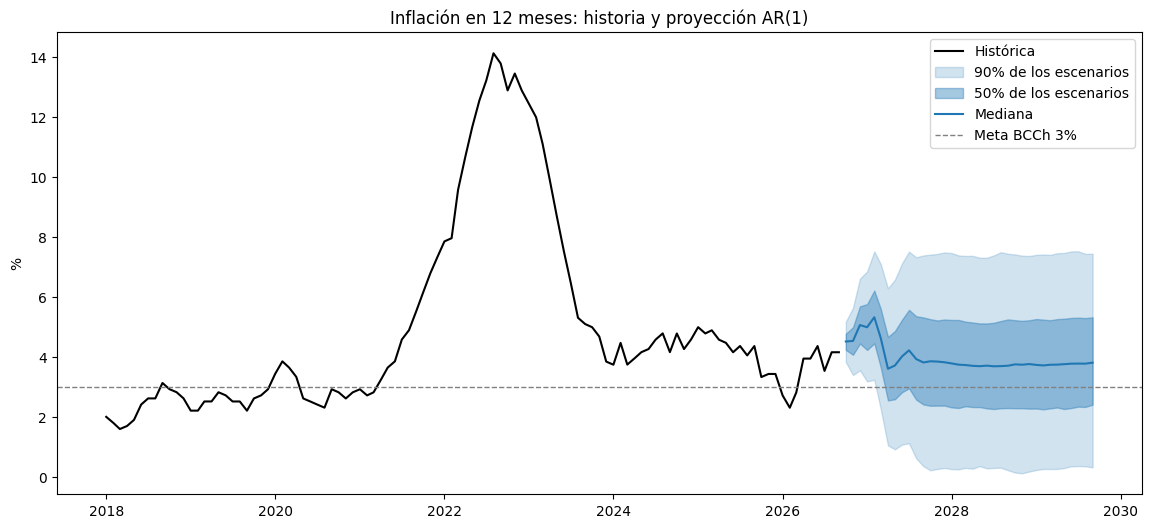

En 12 meses: mediana 3.83% | rango 90%: 0.37% a 7.39% | P(inflación > 5%) = 29.7%
En 24 meses: mediana 3.72% | rango 90%: 0.23% a 7.45% | P(inflación > 5%) = 29.2%
En 36 meses: mediana 3.82% | rango 90%: 0.33% a 7.45% | P(inflación > 5%) = 29.8%


In [12]:
# Simulación de 5000 iteraciones durante 3 años.

rng = np.random.default_rng(42)   # semilla fija: mismo resultado cada vez
N, H = 5000, 36                   # trayectorias y meses a simular

# Simular la inflación mensual: x(t+1) = a + b·x(t) + sigma·shock
x = np.full(N, muestra.iloc[-1])
mensual_sim = np.empty((N, H))
for t in range(H):
    x = a + b * x + sigma * rng.standard_normal(N)
    mensual_sim[:, t] = x

# Pasar a inflación en 12 meses: cada mes simulado se acumula con los 11 anteriores
ultimos_11 = muestra.iloc[-11:].to_numpy()
completo = np.hstack([np.tile(ultimos_11, (N, 1)), mensual_sim])
factores = 1 + completo / 100
infl_12m_sim = np.column_stack([
    (np.prod(factores[:, t:t + 12], axis=1) - 1) * 100 for t in range(H)
])

fechas_futuras = pd.period_range(muestra.index[-1] + 1, periods=H, freq="M")
p5, p25, p50, p75, p95 = np.percentile(infl_12m_sim, [5, 25, 50, 75, 95], axis=0)

# Gráfico: historia desde 2018 + abanico
fig, ax = plt.subplots(figsize=(14, 6))
historia = inflacion_12m["2018-01":]
ax.plot(historia.index.to_timestamp(), historia.values, color="black", label="Histórica")

x_fut = fechas_futuras.to_timestamp()
ax.fill_between(x_fut, p5, p95, alpha=0.2, color="tab:blue", label="90% de los escenarios")
ax.fill_between(x_fut, p25, p75, alpha=0.4, color="tab:blue", label="50% de los escenarios")
ax.plot(x_fut, p50, color="tab:blue", label="Mediana")
ax.axhline(3, color="gray", linestyle="--", linewidth=1, label="Meta BCCh 3%")
ax.set_title("Inflación en 12 meses: historia y proyección AR(1)")
ax.set_ylabel("%")
ax.legend()
plt.show()

for meses in (12, 24, 36):
    prob = (infl_12m_sim[:, meses - 1] > 5).mean() * 100
    print(f"En {meses} meses: mediana {p50[meses - 1]:.2f}% | "
          f"rango 90%: {p5[meses - 1]:.2f}% a {p95[meses - 1]:.2f}% | "
          f"P(inflación > 5%) = {prob:.1f}%")

In [13]:
# Comprobando el modelo con datos reales del dataset.

historia_meta = inflacion_12m["2001-01":]
print(f"Meses con inflación en 12 meses > 5% desde 2001: {(historia_meta > 5).mean() * 100:.1f}%")
print(f"Rango 5%-95% histórico: {historia_meta.quantile(0.05):.2f}% a {historia_meta.quantile(0.95):.2f}%")

Meses con inflación en 12 meses > 5% desde 2001: 16.5%
Rango 5%-95% histórico: 0.99% a 9.58%
